# 06 — Emerging-Issue Detection (Phase 4)

Group similar complaints into topics with **no labels**, then watch which topics
suddenly spike week to week. The classifier in Phases 2–3 could only sort
complaints into products we already knew about. This notebook finds problems
nobody labelled — the "we started getting a wave of X last week" signal.

Plan:
1. Glue the six-month data back together and take a workable sample
2. Turn each narrative into an embedding (sentence-transformers)
3. Cluster the embeddings into topics (BERTopic = UMAP + HDBSCAN)
4. Read the topics and sanity-check they make sense
5. Count each topic week by week
6. Flag spikes with a rolling z-score
7. Write up 5+ emerging-issue case studies with real complaints
8. Chart the spikes, check stability, save a report

Everything here is **inference only** — no model training — so it runs on the
Mac (CPU/MPS), no Colab GPU needed.

## Before you run this

Phase 4 needs a few extra libraries. Install them once into the project venv:

```
pip install sentence-transformers bertopic umap-learn hdbscan
```

The first run also downloads the embedding model (`all-MiniLM-L6-v2`, ~90 MB);
after that it is cached and offline.

In [4]:
pip install sentence-transformers bertopic umap-learn hdbscan

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 611.3/611.3 kB 35.9 kB/s  0:00:21 eta 0:00:03
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.6/2.6 MB 65.2 kB/s  0:00:41 eta 0:00:04
   ━━━━━━━━━━╺━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.2/40.5 MB ? eta -:--:--2:01
Resuming download llvmlite-0.49.0-cp311-cp311-macosx_12_0_arm64.whl (10.2 MB/40.5 MB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 40.5/40.5 MB 5.2 MB/s  0:00:05 eta 0:00:01m
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.7/2.7 MB 7.2 MB/s  0:00:00m eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.9/9.9 MB 7.7 MB/s  0:00:01 eta 0:00:01m
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8/8 [bertopic]6/8 [sentence-transformers]

[notice] A new release of pip is available: 26.1.2 -> 26.2.1
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [1]:
import os
import numpy as np
import pandas as pd

# Work from the project root so the "data/..." paths are correct.
if os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")

# For finding emerging issues we want the FULL six-month timeline at the real
# (natural) class mix - not the balanced training set, which throws rows away.
#   train_natural.parquet = the whole train period, un-balanced
#   test.parquet          = the newest slice
# Glue them back together and sort oldest -> newest.
train_natural = pd.read_parquet("data/processed/train_natural.parquet")
test = pd.read_parquet("data/processed/test.parquet")

complaints = pd.concat([train_natural, test], ignore_index=True)
complaints["date_received"] = pd.to_datetime(complaints["date_received"])
complaints = complaints.sort_values("date_received").reset_index(drop=True)

print("total complaints:", len(complaints))
print("date range:", complaints["date_received"].min().date(),
      "to", complaints["date_received"].max().date())

total complaints: 173468
date range: 2023-01-01 to 2023-06-30


## 1) Take a workable sample

Embedding all 170k+ narratives is slow and memory-heavy, and we do not need
every one to see the weekly trends. Take a random sample to keep the notebook
comfortable on a laptop. Raise `SAMPLE_SIZE` (or set it to `None` to use
everything) if your machine has the time and RAM.

In [2]:
SAMPLE_SIZE = 40000   # set to None to embed every complaint

if SAMPLE_SIZE is not None and SAMPLE_SIZE < len(complaints):
    sample = complaints.sample(n=SAMPLE_SIZE, random_state=42)
else:
    sample = complaints

# Re-sort by date after sampling, because we chart things over time later.
sample = sample.sort_values("date_received").reset_index(drop=True)

# The text the model will read, as a plain Python list.
docs = sample["consumer_complaint_narrative"].tolist()

print("using", len(sample), "narratives")
print("from", sample["date_received"].min().date(),
      "to", sample["date_received"].max().date())

using 40000 narratives
from 2023-01-01 to 2023-06-30


## 2) Turn each narrative into an embedding

An embedding is a list of 384 numbers describing what a complaint is *about*.
Complaints that mean similar things get similar numbers, so "close together" =
"similar complaint". `all-MiniLM-L6-v2` is a small, fast, well-tested model that
runs fine on a laptop with no GPU.

In [3]:
# The first run downloads the model (~90 MB); after that it is cached.
import time
from sentence_transformers import SentenceTransformer

embedder = SentenceTransformer("all-MiniLM-L6-v2")

start = time.time()
embeddings = embedder.encode(docs, batch_size=64, show_progress_bar=True)
print("embedded", len(docs), "narratives in", round(time.time() - start), "seconds")
print("embedding shape:", embeddings.shape)

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md: 0.00B [00:00, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/90.9M [00:00<?, ?B/s]

... (3 outputs left out)

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

Batches:   0%|          | 0/625 [00:00<?, ?it/s]

embedded 40000 narratives in 131 seconds
embedding shape: (40000, 384)


## 3) Cluster into topics with BERTopic

BERTopic does three things for us:
- **UMAP** squeezes the 384 numbers down to a few, so clustering is tractable.
- **HDBSCAN** finds dense clumps — each clump is a topic. Leftover points it is
  not sure about go into topic `-1` ("no clear topic"). Some outliers are normal
  and expected.
- **c-TF-IDF** reads each clump and picks the words that define it.

Two honesty details:
- We fix the random seeds so the run is repeatable.
- The narratives are full of `XXXX` privacy masks. Left alone, "xxxx" would
  become the top word of every topic, so we add the masks to the stop-word list.

`n_neighbors` and `min_cluster_size` are the two knobs worth tuning: a bigger
`min_cluster_size` gives fewer, broader topics; a smaller one gives more, finer
topics.

In [4]:
from bertopic import BERTopic
from umap import UMAP
from hdbscan import HDBSCAN
from sklearn.feature_extraction.text import CountVectorizer, ENGLISH_STOP_WORDS

# Ignore the redaction masks so topics are about real words.
stop_words = list(ENGLISH_STOP_WORDS) + ["xx", "xxx", "xxxx", "xxxxxxxx"]
vectorizer = CountVectorizer(stop_words=stop_words, ngram_range=(1, 2), min_df=10)

umap_model = UMAP(n_neighbors=15, n_components=5, min_dist=0.0,
                  metric="cosine", random_state=42)
hdbscan_model = HDBSCAN(min_cluster_size=150, metric="euclidean",
                        cluster_selection_method="eom", prediction_data=True)

topic_model = BERTopic(umap_model=umap_model, hdbscan_model=hdbscan_model,
                       vectorizer_model=vectorizer, calculate_probabilities=False,
                       verbose=True)

# Pass the embeddings we already made so BERTopic does not recompute them.
topics, probs = topic_model.fit_transform(docs, embeddings)

# Keep the topic assignment next to each complaint for the time analysis below.
sample["topic"] = topics

n_topics = len([t for t in set(topics) if t != -1])
outlier_share = round(100 * (sample["topic"] == -1).mean(), 1)
print("found", n_topics, "topics")
print("outliers (topic -1):", outlier_share, "%")

2026-08-13 14:44:33,361 - BERTopic - Dimensionality - Fitting the dimensionality reduction algorithm
2026-08-13 14:44:57,450 - BERTopic - Dimensionality - Completed ✓
2026-08-13 14:44:57,452 - BERTopic - Cluster - Start clustering the reduced embeddings
2026-08-13 14:45:00,582 - BERTopic - Cluster - Completed ✓
2026-08-13 14:45:00,589 - BERTopic - Representation - Fine-tuning topics using representation models.
2026-08-13 14:45:03,482 - BERTopic - Representation - Completed ✓


found 40 topics
outliers (topic -1): 38.9 %


## 4) Read the topics and sanity-check them

`Count` is how many complaints landed in each topic; `Name` is BERTopic's
auto-label from the top words. The roadmap's definition of done is exactly this:
*a non-technical person can read the topic words and understand what each cluster
is.* If a topic's words are gibberish, that is a signal to retune
`min_cluster_size`.

In [5]:
topic_info = topic_model.get_topic_info()
print(topic_info[["Topic", "Count", "Name"]].head(20).to_string(index=False))

 Topic  Count                                                        Name
    -1  15550                        -1_credit_information_report_account
     0   3835                            0_debt_collection_company_credit
     1   3064                                   1_bank_card_account_money
     2   1337                             2_inquiries_inquiry_hard_credit
     3   1171                              3_mortgage_loan_payment_escrow
     4    861                                    4_15 usc_usc_15_consumer
     5    836                                  5_car_vehicle_loan_payment
     6    789                            6_accounts_account_credit_report
     7    766                        7_section_1681 section_1681_usc 1681
     8    761                             8_15 usc_usc_account account_15
     9    706                             9_fargo_wells_wells fargo_money
    10    691                                  10_balance_items_theft_000
    11    649                      11_

In [6]:
# The defining words of the biggest real topics (skip -1, the leftovers).
real_topics = [t for t in topic_info["Topic"] if t != -1]

for topic_id in real_topics[:15]:
    words = [word for word, score in topic_model.get_topic(topic_id)]
    print("topic", topic_id, "->", ", ".join(words[:8]))

topic 0 -> debt, collection, company, credit, validation, collector, received, letter
topic 1 -> bank, card, account, money, told, check, called, funds
topic 2 -> inquiries, inquiry, hard, credit, unauthorized, credit report, report, hard inquiries
topic 3 -> mortgage, loan, payment, escrow, payments, home, insurance, property
topic 4 -> 15 usc, usc, 15, consumer, reporting agency, consumer reporting, section, usc 1681
topic 5 -> car, vehicle, loan, payment, payments, finance, told, paid
topic 6 -> accounts, account, credit, report, credit report, identity, fraudulent, removed
topic 7 -> section, 1681 section, 1681, usc 1681, states, violated rights, accordance fair, accordance
topic 8 -> 15 usc, usc, account account, 15, consumer, usc 1681, section, reporting agency
topic 9 -> fargo, wells, wells fargo, money, account, bank, claim, fees
topic 10 -> balance, items, theft, 000, 605b, balance 000, creditor balance, original creditor
topic 11 -> late, payments, payment, late payments, lat

## 5) Count each topic week by week

Drop the `-1` leftovers, bucket every complaint into the week it arrived in
(weeks start Monday), and count per `(topic, week)`. This weekly table is what
we watch for spikes.

In [ ]:
timed = sample[sample["topic"] != -1].copy()
timed["week"] = timed["date_received"].dt.to_period("W").dt.start_time

weekly_counts = (timed
                 .groupby(["topic", "week"])
                 .size()
                 .reset_index(name="count"))

print("weeks covered:", timed["week"].nunique())
print(weekly_counts.head())

weeks covered: 27
   topic       week  count
0      0 2022-12-26     11
1      0 2023-01-02    155
2      0 2023-01-09    134
3      0 2023-01-16    156
4      0 2023-01-23    172


## 6) Flag spikes with a rolling z-score

For each topic we walk its weekly counts in date order and compare each week to
its own recent past: how many standard deviations above the local average is it?
That number is the **z-score**. A big z-score means "this week is unusually busy
for this topic" — an emerging issue.

Settings, kept conservative so tiny topics do not fire on noise:
- look back **6 weeks** for the local average,
- a week must be **≥ 2 std** above that average,
- and have **≥ 15 complaints** that week.

In [8]:
Z_THRESHOLD = 2.0
MIN_COUNT = 15
WINDOW = 6

spikes = []
for topic_id in weekly_counts["topic"].unique():
    one = weekly_counts[weekly_counts["topic"] == topic_id].sort_values("week")
    counts = one["count"]

    # Average and spread of the WINDOW weeks BEFORE each week. shift(1) excludes
    # the current week, so each week is judged against its own history only.
    rolling_mean = counts.shift(1).rolling(WINDOW, min_periods=3).mean()
    rolling_std = counts.shift(1).rolling(WINDOW, min_periods=3).std()

    z = (counts - rolling_mean) / rolling_std
    z = z.replace([np.inf, -np.inf], np.nan)   # guard flat histories (std = 0)

    one = one.assign(z_score=z)
    hits = one[(one["z_score"] >= Z_THRESHOLD) & (one["count"] >= MIN_COUNT)]
    for _, row in hits.iterrows():
        spikes.append([topic_id, row["week"], int(row["count"]), round(row["z_score"], 2)])

spikes = pd.DataFrame(spikes, columns=["topic", "week", "count", "z_score"])
spikes = spikes.sort_values("z_score", ascending=False).reset_index(drop=True)

print("detected", len(spikes), "topic-week spikes")
print(spikes.head(15).to_string(index=False))

detected 54 topic-week spikes
 topic       week  count  z_score
    26 2023-01-16     46    21.50
     9 2023-01-16    146    16.66
    32 2023-01-23     57    14.42
    19 2023-04-10     30     6.89
    38 2023-03-20     22     6.88
    28 2023-01-16     19     5.08
    28 2023-05-08     18     4.72
    12 2023-02-27     37     4.63
    15 2023-03-06     51     4.27
    14 2023-06-05     36     4.20
    27 2023-05-08     18     4.04
    20 2023-03-06     15     3.95
    37 2023-03-13     15     3.94
     3 2023-05-01     68     3.89
    23 2023-03-27     16     3.87


## 7) Case studies — what were the spikes actually about?

For each of the biggest spikes, print the topic's words, the week it jumped, and
a few real complaints from that exact topic-and-week. This is the payoff: an
analyst can read these and immediately see the emerging issue.

In [9]:
def topic_label(topic_id):
    words = [word for word, score in topic_model.get_topic(topic_id)]
    return ", ".join(words[:6])

top_spikes = spikes.head(6)

for _, s in top_spikes.iterrows():
    topic_id = s["topic"]
    week = s["week"]
    print("=" * 80)
    print("TOPIC", topic_id, "->", topic_label(topic_id))
    print("spiked week of", week.date(), "| count", s["count"], "| z-score", s["z_score"])
    print("-" * 80)

    examples = timed[(timed["topic"] == topic_id) & (timed["week"] == week)]
    for _, row in examples.head(3).iterrows():
        text = row["consumer_complaint_narrative"][:280].replace("\n", " ")
        print("[complaint", row["complaint_id"], "]", text, "...")
        print()

TOPIC 26 -> wells, fargo, wells fargo, mortgage, loan, home
spiked week of 2023-01-16 | count 46 | z-score 21.5
--------------------------------------------------------------------------------
[complaint 6444399 ] XXXX XXXX XXXX auto loan was purchased for {$17000.00} with a loan period of XXXX  years XXXX from XXXX XXXX XXXX via Wells Fargo. Over the past XXXX XXXX XXXX  during the duration of XXXX it was difficult to may payments of {$380.00}. During that time my aunt was residing in a X ...

[complaint 6447290 ] I Financed a car through wells fargo in XX/XX/XXXX from XXXX XXXX of XXXX Arizona. I have made 10 payments on it and wells fargo has yet to report them to any credit bureau. I have called multiple times and they say to mail a letter to the corporate office like its XXXX. I have s ...

[complaint 6454069 ] I filed bankruptcy about 12 years ago on my credit cards not against my mortgage with Wells Fargo mortgage, they lied to the lawyer that I was behind and did not put my pay

## 8) Chart the spiking topics

Plot the weekly volume of the top spiking topics and mark where each spike fired
(red dot). Saved to `reports/figures/` like the other notebooks' charts.

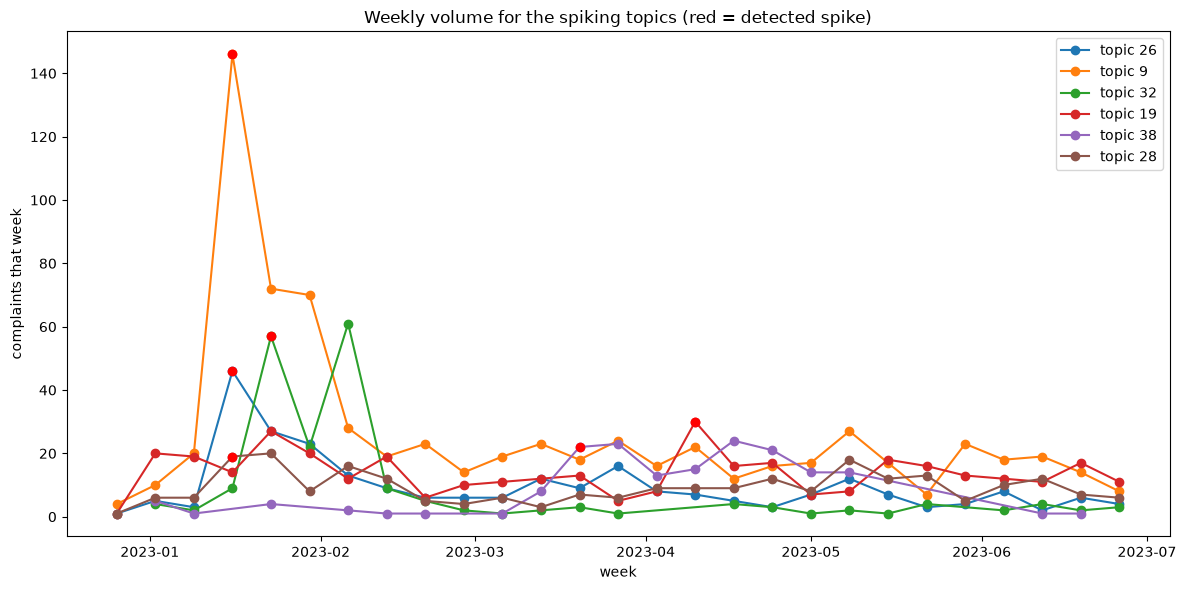

saved reports/figures/topic_spikes.png


In [10]:
import matplotlib.pyplot as plt

os.makedirs("reports/figures", exist_ok=True)

topics_to_plot = top_spikes["topic"].unique()[:6]

plt.figure(figsize=(12, 6))
for topic_id in topics_to_plot:
    one = weekly_counts[weekly_counts["topic"] == topic_id].sort_values("week")
    plt.plot(one["week"], one["count"], marker="o", label="topic " + str(topic_id))

# Mark each detected spike with a red dot.
for _, s in top_spikes.iterrows():
    plt.scatter([s["week"]], [s["count"]], color="red", zorder=5)

plt.title("Weekly volume for the spiking topics (red = detected spike)")
plt.xlabel("week")
plt.ylabel("complaints that week")
plt.legend()
plt.tight_layout()
plt.savefig("reports/figures/topic_spikes.png", dpi=120)
plt.show()
print("saved reports/figures/topic_spikes.png")

## 9) Stability check (honesty)

Clustering is a bit random: change the seed and the topics shift slightly. We
refit BERTopic on the **same embeddings** with a different UMAP seed and measure
how much the two groupings agree, using the Adjusted Rand Index (1.0 = identical
grouping, 0.0 = random agreement). This runs a second clustering, so flip the
flag off to skip it.

In [11]:
RUN_STABILITY_CHECK = True

if RUN_STABILITY_CHECK:
    from sklearn.metrics import adjusted_rand_score

    umap_model_2 = UMAP(n_neighbors=15, n_components=5, min_dist=0.0,
                        metric="cosine", random_state=99)
    hdbscan_model_2 = HDBSCAN(min_cluster_size=150, metric="euclidean",
                              cluster_selection_method="eom")
    topic_model_2 = BERTopic(umap_model=umap_model_2, hdbscan_model=hdbscan_model_2,
                             vectorizer_model=vectorizer, calculate_probabilities=False,
                             verbose=False)
    topics_2, _ = topic_model_2.fit_transform(docs, embeddings)

    ari = adjusted_rand_score(topics, topics_2)
    n_topics_2 = len([t for t in set(topics_2) if t != -1])
    print("run 1 topics:", n_topics, " run 2 topics:", n_topics_2)
    print("Adjusted Rand Index between the two runs:", round(ari, 3))
else:
    ari = None
    n_topics_2 = None
    print("stability check skipped")

run 1 topics: 40  run 2 topics: 39
Adjusted Rand Index between the two runs: 0.755


## 10) Save the per-complaint topics

Save which topic each complaint landed in, so Phase 5 (the grounded LLM brief)
can pull real example complaints for any topic later. Parquet keeps it small.

In [12]:
keep = sample[["complaint_id", "date_received", "product", "topic",
               "consumer_complaint_narrative"]]
keep.to_parquet("data/processed/complaint_topics.parquet", index=False)
print("saved data/processed/complaint_topics.parquet:", len(keep), "rows")

saved data/processed/complaint_topics.parquet: 40000 rows


## 11) Write the report

Write a short report with the real numbers from **this** run, the way the other
notebooks do. Open `reports/topics_report.md` afterwards.

In [13]:
import datetime

lines = []
lines.append("# Phase 4 - Emerging-issue detection")
lines.append("")
lines.append("Generated by `notebooks/06_topics_over_time.ipynb` on " + str(datetime.date.today()) + ".")
lines.append("")
lines.append("Method: all-MiniLM-L6-v2 embeddings -> BERTopic (UMAP + HDBSCAN) -> "
             "weekly topic volumes -> rolling z-score spike detection.")
lines.append("")
lines.append("## Data")
lines.append("")
lines.append("- Narratives used: " + str(len(sample)) + " (random sample of " +
             str(len(complaints)) + " six-month complaints; SAMPLE_SIZE=" + str(SAMPLE_SIZE) + ").")
lines.append("- Date range: " + str(sample["date_received"].min().date()) +
             " to " + str(sample["date_received"].max().date()) + ".")
lines.append("")
lines.append("## Topics")
lines.append("")
lines.append("- Topics found: " + str(n_topics) + ".")
lines.append("- Outliers (no clear topic, -1): " + str(outlier_share) + "%.")
lines.append("")
lines.append("Biggest topics:")
lines.append("")
lines.append("```")
lines.append(topic_info[["Topic", "Count", "Name"]].head(15).to_string(index=False))
lines.append("```")
lines.append("")
lines.append("## Detected spikes (emerging issues)")
lines.append("")
lines.append("Rule: a topic's weekly count is >= " + str(Z_THRESHOLD) +
             " standard deviations above its own trailing " + str(WINDOW) +
             "-week average, with at least " + str(MIN_COUNT) + " complaints that week.")
lines.append("")
lines.append("- Total topic-week spikes: " + str(len(spikes)) + ".")
lines.append("")
lines.append("Top spikes:")
lines.append("")
lines.append("```")
if len(spikes) > 0:
    lines.append(spikes.head(10).to_string(index=False))
else:
    lines.append("none detected at these settings")
lines.append("```")
lines.append("")
lines.append("## Case studies")
lines.append("")
for _, s in spikes.head(6).iterrows():
    lines.append("- **Topic " + str(s["topic"]) + "** (" + topic_label(s["topic"]) +
                 ") spiked the week of " + str(s["week"].date()) +
                 ": " + str(s["count"]) + " complaints, z-score " + str(s["z_score"]) + ".")
if len(spikes) == 0:
    lines.append("- No spikes at the current thresholds - lower Z_THRESHOLD or MIN_COUNT and rerun.")
lines.append("")
lines.append("## Stability")
lines.append("")
if ari is not None:
    lines.append("Refitting on the same embeddings with a different seed gave " +
                 str(n_topics_2) + " topics (vs " + str(n_topics) +
                 "), Adjusted Rand Index " + str(round(ari, 3)) +
                 " (1.0 = identical grouping). Topic *numbers* change between runs; "
                 "the broad themes are what stay stable.")
else:
    lines.append("Stability check was skipped this run (RUN_STABILITY_CHECK = False).")
lines.append("")
lines.append("## Figure")
lines.append("")
lines.append("![topic spikes](figures/topic_spikes.png)")
lines.append("")
lines.append("## Honest limitations")
lines.append("")
lines.append("- Only ~26 weeks of history, so spike detection is illustrative, not battle-tested.")
lines.append("- Topic assignments are unsupervised and shift with the seed (see Stability). "
             "Use the themes, not the exact topic ids.")
lines.append("- A random sample was embedded for speed; raising SAMPLE_SIZE steadies the weekly counts.")

with open("reports/topics_report.md", "w") as f:
    f.write("\n".join(lines) + "\n")
print("saved reports/topics_report.md")

saved reports/topics_report.md


## Takeaways

What this phase adds to the story:

- **Unsupervised discovery.** The classifier only knows the 9 products we labelled.
  This layer finds sub-themes *inside* them with no labels at all — the honest
  answer to "how would you catch a problem you'd never seen before?"
- **A working early-warning signal.** The rolling z-score turns "topic volume" into
  "which topics are unusually busy this week", with concrete complaint examples
  behind each alert.
- **Honesty about limits.** Topics move with the random seed; the Adjusted Rand
  Index quantifies exactly how much, and the report says to trust the themes, not
  the topic numbers. Six months is a short history — stated plainly.
- **Feeds Phase 5.** `data/processed/complaint_topics.parquet` gives the grounded
  LLM brief real, citable complaints per topic to retrieve.

Open `reports/topics_report.md` and `reports/figures/topic_spikes.png` for the
exact results from your run.